# PERTEMUAN 8 — PRAKTIKUM PEMBELAJARAN MESIN
## **Bagaimana EDA dan preprocessing menentukan pilihan Hierarchical Clustering atau K-Means?**

**DAIS32W · 150 menit praktikum · Praktikum individual **

> **Tujuan:** Mahasiswa dapat: (a) membuktikan keterkaitan materi Pertemuan 1–7 dengan struktur clustering; (b) mengaudit apakah jarak dan model layak diuji; (c) membandingkan Ward dan K-Means dengan data, fitur dan k yang sebanding; (d) melakukan ablation dan mempertanggungjawabkan keputusan tanpa label; serta (e) menyusun portofolio satu notebook dengan tabel eksperimen dan profil cluster..

**Sebelum mulai**

1. Buka notebook di Jupyter/Google Colab/Kaggle; gunakan *Python 3* dengan `numpy`, `pandas`, `matplotlib`, `scipy`, dan `scikit-learn`.
2. Jalankan cell berurutan dari atas ke bawah. Tulis jawaban di setiap kotak **✍️ JAWABAN ANDA** (ubah sel Markdown dengan *double click*).
3. **Jangan mengubah label cultivar Wine menjadi fitur**, atau menggunakannya untuk memilih model. Cluster tidak mempunyai label benar untuk pelatihan.
4. Setiap tabel/grafik perlu diinterpretasikan. Tidak cukup hanya screenshot atau menulis “skor meningkat”.
5. **Pilih algoritma berdasarkan dua jenis bukti:** kelayakan awal dari EDA, dan hasil perbandingan yang menggunakan representasi/evaluasi setara. Hasilnya boleh berbeda dari contoh dosen bila ada penjelasan yang benar.

**Identitas:** NIM: `ISI_NIM` · Nama: `ISI_NAMA` · Tanggal: `30 Oktober 2026`.

### Peta hubungan teori P1–P7 dengan praktikum P8

| Materi terdahulu | Apa yang diuji dalam praktikum ini? | Bukti yang harus muncul |
|:--|:--|:--|
| **P1 — Problem framing & tipe belajar** | Kapan mencari kelompok tanpa label? Apa tujuan analisis? | Rumusan tujuan + unit analisis |
| **P2 — Vektor, matriks, jarak, objektif** | Jarak Euclidean, centroid/inertia, Ward ΔSSE | Cocokkan contoh enam Wine dari teori |
| **P3 — Desain eksperimen & generalisasi** | Perbandingan adil, satu perubahan per run, tidak memilih atas label tersembunyi | Tabel ablation + keterbatasan |
| **P4 — EDA & kualitas data** | Tipe fitur, sebaran, missing, duplikasi, outlier, korelasi | Issue log berdasar angka |
| **P5 — Cleaning & preprocessing** | Imputasi, scaling, penanganan nilai ekstrem, dampak transformasi | Hasil raw vs StandardScaler dan data terganggu |
| **P6 — Feature selection & PCA** | Redundansi, korelasi, kehilangan informasi | Perbandingan full vs selection vs PCA |
| **P7 — UTS integrasi** | Audit keputusan, eksperimen tercatat, keterulangan | FINAL_DECISION + README GitHub |

*Catatan*: Split training/validation/test tidak otomatis diwajibkan untuk **eksplorasi unsupervised deskriptif** atas satu kumpulan data. Jika metode akan diterapkan atau diklaim menggeneralisasi ke data baru, preprocessing serta evaluasi keluar-sampel harus dirancang secara terpisah. Jangan mengira bahwa cluster selalu memiliki ground truth.

## P0 — Memulai tanpa mengubah konfigurasi algoritma
**JALANKAN:** cell import, versi pustaka, dan seed. Notebook memakai dataset bawaan scikit-learn; **tidak memerlukan internet maupun CSV eksternal**. Jika `ModuleNotFoundError`, instal library pada environment Jupyter/Colab yang sesuai, lalu mulai ulang kernel.

In [1]:
import sys, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_wine, make_blobs, make_moons
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
import sklearn, scipy
from IPython.display import display

SEED = 2026
rng = np.random.default_rng(SEED)
OUTDIR = Path('P08_output')
OUTDIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 15)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__, '| SciPy:', scipy.__version__)
print('Random seed:', SEED, '| Output:', OUTDIR.resolve())

Python: 3.14.7 | scikit-learn: 1.9.1 | SciPy: 1.18.1
Random seed: 2026 | Output: D:\MLGITHUB\P08_output


## P1 — Dari hitungan teori ke Python
**SUMBER NYATA:** `sklearn.datasets.load_wine()` (178 sampel, 13 fitur numerik). Pengelompokan **tidak memakai** `wine.target`. Contoh dari teori memilih indeks `[0,2,59,60,175,176]` dan dua fitur (`alcohol`, `color_intensity`).

**JALANKAN:** tampilkan enam observasi, jarak A–B, dan dua skenario kelompok S1/S2. Cocokkan dengan Bagian 6 materi teori.

In [2]:
wine = load_wine(as_frame=True)
X_raw = wine.data.copy()   # HANYA fitur kimia; label cultivar wine.target tidak masuk
X_raw.index.name = 'row_id'
contoh_id = [0, 2, 59, 60, 175, 176]
contoh = X_raw.loc[contoh_id, ['alcohol', 'color_intensity']].copy()
contoh.index = list('ABCDEF')
print('Dataset:', X_raw.shape, '| Target tersedia untuk sumber, tetapi TIDAK dimasukkan ke clustering.')
display(contoh)
dist = squareform(pdist(contoh.to_numpy(), metric='euclidean'))
print('Jarak A-B =', round(dist[0,1],4), '(teori ≈ 1.0707)')
S1 = [0,0,1,1,2,2]   # A,B | C,D | E,F
S2 = [0,1,0,1,2,2]   # A,C | B,D | E,F
print('Silhouette S1 =', round(silhouette_score(contoh, S1),4), '(teori ≈ 0.686)')
print('Silhouette S2 =', round(silhouette_score(contoh, S2),4), '(teori ≈ 0.098)')
assert X_raw.shape == (178, 13)

Dataset: (178, 13) | Target tersedia untuk sumber, tetapi TIDAK dimasukkan ke clustering.


,alcohol,color_intensity
A,14.23,5.64
B,13.16,5.68
C,12.37,1.95
D,12.33,3.27
E,13.27,10.20
F,13.17,9.30


Jarak A-B = 1.0707 (teori ≈ 1.0707)
Silhouette S1 = 0.6864 (teori ≈ 0.686)
Silhouette S2 = 0.0979 (teori ≈ 0.098)


**✍️ JAWABAN ANDA — P1.** Apa arti label `S1`/`S2`? Mengapa rata-rata silhouette dapat berbeda meski nilai keenam observasi sama? Jelaskan apakah hasil enam baris sudah bisa menjadi kesimpulan untuk seluruh Wine Dataset.

**Jawab di sini:** Output Python cocok dengan teori: jarak A–B = **1.0707**, silhouette S1 = **0.6864** (teori ≈ 0.686), dan S2 = **0.0979** (teori ≈ 0.098).

- **Arti S1/S2.** `S1` dan `S2` adalah dua *skenario penugasan kelompok* yang kita tetapkan sendiri untuk enam titik yang sama. S1 = {A,B} | {C,D} | {E,F}; S2 = {A,C} | {B,D} | {E,F}. Angka 0/1/2 hanya penanda kelompok, bukan kelas atau label cultivar.
- **Mengapa silhouette berbeda.** Koordinat keenam observasi tidak berubah, tetapi silhouette menilai *partisi*: untuk tiap titik dihitung a = rata-rata jarak ke anggota kelompoknya sendiri dan b = rata-rata jarak ke kelompok terdekat lain, lalu s = (b − a)/max(a, b). Di S1, A dan B berdekatan (jarak 1.07) sehingga a kecil dan s tinggi. Di S2, A dipasangkan dengan C (alcohol 12.37, color 1.95) yang jauh, padahal B lebih dekat ke A daripada C, sehingga a membesar dan s turun. Jadi skor bergantung pada cara titik dikelompokkan, bukan hanya pada datanya.
- **Bisa digeneralisasi?** Belum. Enam baris dan dua dari 13 fitur hanya ilustrasi mekanisme hitungan. Keenam baris itu dipilih secara sengaja (bukan sampel acak), dan tidak mewakili sebaran 178 sampel × 13 fitur, perbedaan skala (misalnya `proline` ratusan–ribuan), maupun korelasi antarfitur. Kesimpulan tentang seluruh Wine harus diambil dari EDA dan clustering pada data lengkap (P2–P7).

## P2 — EDA sebelum clustering: apakah metode berbasis jarak masuk akal?

> **Pertanyaan keputusan:** dataset berukuran berapa, fitur apa yang tersedia, adakah kualitas data bermasalah, apakah skala timpang, apakah banyak fitur redundan, dan apakah perlu mengeksplorasi hierarki?

### P2-A. Profil data dan audit missing/duplikasi
**JALANKAN:** lihat `head`, ukuran, tipe data, missing, duplikasi, rentang, dan sebaran. **Jangan langsung scaling / clustering**.

In [3]:
display(X_raw.head(5))
report_eda = pd.DataFrame({
    'dtype':X_raw.dtypes.astype(str),
    'missing':X_raw.isna().sum(),
    'mean':X_raw.mean(),
    'std':X_raw.std(ddof=0),
    'min':X_raw.min(),
    'median':X_raw.median(),
    'max':X_raw.max(),
})
report_eda['range'] = report_eda['max'] - report_eda['min']
print('Ukuran n,p:', X_raw.shape)
print('Total missing:', int(X_raw.isna().sum().sum()))
print('Duplikat persis:', int(X_raw.duplicated().sum()))
print('Fitur konstan:', list(X_raw.columns[X_raw.nunique() <= 1]))
print('Rasio rentang terbesar/terkecil =', round(report_eda['range'].max()/report_eda['range'].min(),2))
display(report_eda.round(3))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
row_id,,,,,,,,,,,,,
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ukuran n,p: (178, 13)
Total missing: 0
Duplikat persis: 0
Fitur konstan: []
Rasio rentang terbesar/terkecil = 2645.28


,dtype,missing,mean,std,min,median,max,range
alcohol,float64,0,13.001,0.810,11.03,13.050,14.83,3.80
malic_acid,float64,0,2.336,1.114,0.74,1.865,5.80,5.06
ash,float64,0,2.367,0.274,1.36,2.360,3.23,1.87
alcalinity_of_ash,float64,0,19.495,3.330,10.60,19.500,30.00,19.40
magnesium,float64,0,99.742,14.242,70.00,98.000,162.00,92.00
total_phenols,float64,0,2.295,0.624,0.98,2.355,3.88,2.90
flavanoids,float64,0,2.029,0.996,0.34,2.135,5.08,4.74
nonflavanoid_phenols,float64,0,0.362,0.124,0.13,0.340,0.66,0.53
proanthocyanins,float64,0,1.591,0.571,0.41,1.555,3.58,3.17
color_intensity,float64,0,5.058,2.312,1.28,4.690,13.00,11.72


### P2-B. Distribusi, outlier, dan seberapa timpang skala fitur?
**JALANKAN:** tinjau histogram beberapa fitur dan jumlah nilai di luar batas IQR (indikasi statistik, bukan otomatis kesalahan). Tingginya skala `proline` perlu dibandingkan dengan fitur berskala kecil.

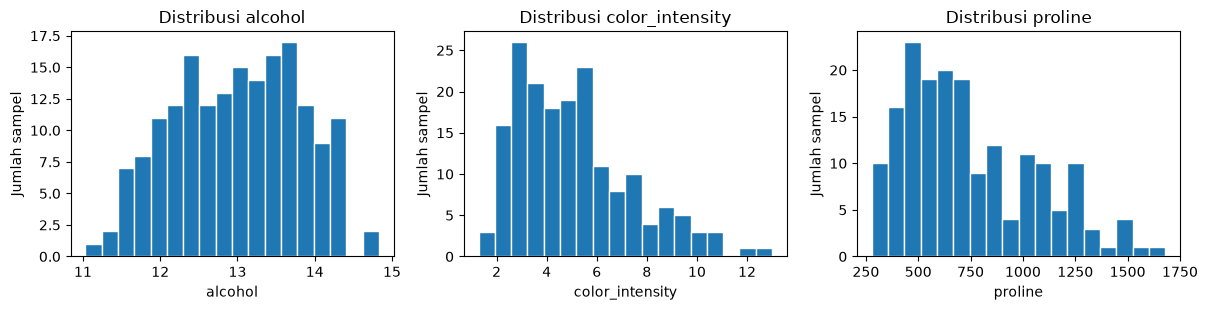

Jumlah observasi di luar batas 1.5×IQR per fitur (tidak otomatis dihapus):


,jumlah_outlier
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0


In [4]:
selected = ['alcohol', 'color_intensity', 'proline']
fig, axes = plt.subplots(1,3, figsize=(12,3.2))
for ax,col in zip(axes, selected):
    ax.hist(X_raw[col], bins=18, edgecolor='white')
    ax.set_title(f'Distribusi {col}'); ax.set_xlabel(col); ax.set_ylabel('Jumlah sampel')
plt.tight_layout(); plt.show()
q1, q3 = X_raw.quantile(.25), X_raw.quantile(.75)
iqr = q3-q1
outlier_iqr = ((X_raw.lt(q1-1.5*iqr)) | (X_raw.gt(q3+1.5*iqr))).sum()
print('Jumlah observasi di luar batas 1.5×IQR per fitur (tidak otomatis dihapus):')
display(outlier_iqr.sort_values(ascending=False).rename('jumlah_outlier').to_frame().head(8))

### P2-C. Korelasi, kedekatan, dan tampilan dua dimensi
**JALANKAN:** perhatikan korelasi absolut tertinggi, lalu bandingkan histogram jarak pasangan pada data mentah vs distandardisasi. Angka jarak antarrepresentasi **tidak dapat dibandingkan sebagai jarak bersatuan sama**. Scatter 2D hanyalah proyeksi dua fitur, bukan gambaran lengkap 13 dimensi.

Pasangan korelasi absolut terbesar:


,,abs(Pearson r)
total_phenols,flavanoids,0.864564
flavanoids,od280/od315_of_diluted_wines,0.787194
total_phenols,od280/od315_of_diluted_wines,0.699949
flavanoids,proanthocyanins,0.652692
alcohol,proline,0.643720
total_phenols,proanthocyanins,0.612413


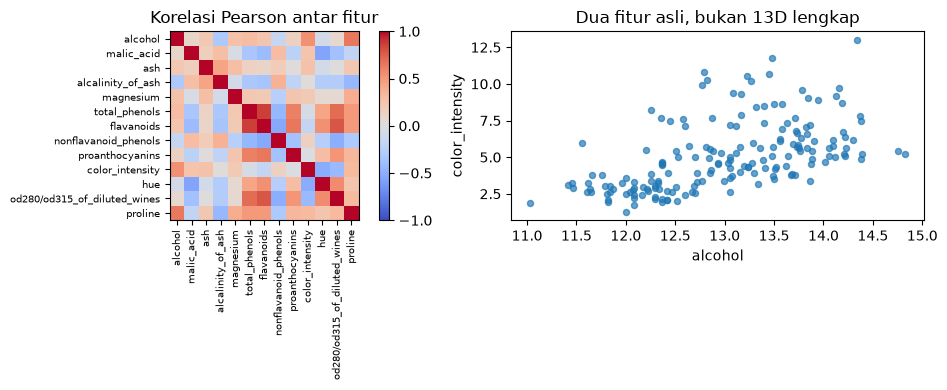

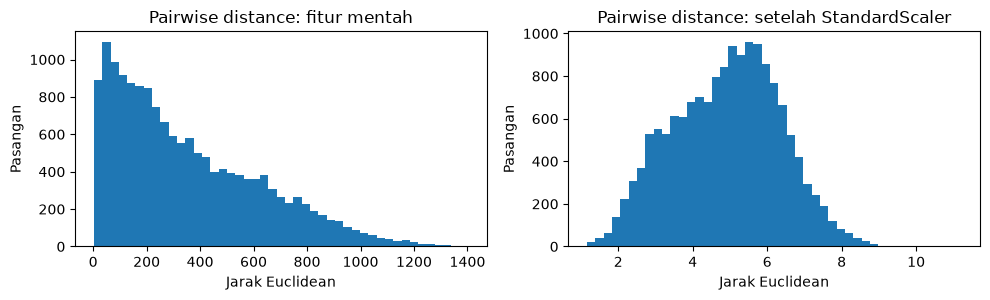

Median pairwise raw: 282.172 | standardized: 5.004


In [5]:
corr = X_raw.corr(numeric_only=True)
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
flat = upper.stack().sort_values(ascending=False)
print('Pasangan korelasi absolut terbesar:')
display(flat.head(6).rename('abs(Pearson r)').to_frame())
fig, axes=plt.subplots(1,2,figsize=(11,4))
im=axes[0].imshow(corr, vmin=-1,vmax=1,cmap='coolwarm')
axes[0].set_xticks(range(13), labels=X_raw.columns, rotation=90, fontsize=7)
axes[0].set_yticks(range(13), labels=X_raw.columns, fontsize=7)
axes[0].set_title('Korelasi Pearson antar fitur')
plt.colorbar(im,ax=axes[0],fraction=.047)
axes[1].scatter(X_raw['alcohol'],X_raw['color_intensity'],alpha=.68,s=19)
axes[1].set_title('Dua fitur asli, bukan 13D lengkap')
axes[1].set_xlabel('alcohol'); axes[1].set_ylabel('color_intensity')
plt.tight_layout();plt.show()
X_std = StandardScaler().fit_transform(X_raw)
draw, dstd = pdist(X_raw.to_numpy()), pdist(X_std)
fig,axes=plt.subplots(1,2,figsize=(10,3.1))
axes[0].hist(draw,bins=45);axes[0].set_title('Pairwise distance: fitur mentah')
axes[1].hist(dstd,bins=45);axes[1].set_title('Pairwise distance: setelah StandardScaler')
for ax in axes: ax.set_xlabel('Jarak Euclidean');ax.set_ylabel('Pasangan')
plt.tight_layout();plt.show()
print('Median pairwise raw:',round(float(np.median(draw)),3),'| standardized:',round(float(np.median(dstd)),3))

### P2-D. **WAJIB: issue log sebelum model pertama**
Isi **minimal lima temuan numerik**. Contoh yang benar: “Jumlah missing = ..., sehingga imputasi pada dataset asli [perlu/tidak perlu]”. Temuan dapat menyatakan tidak ditemukan masalah; jangan menciptakan masalah yang tidak ada.

| Temuan/isu data | Bukti angka/tabel dari output | Risiko untuk jarak/cluster | Keputusan sementara |
|---|---|---|---|
| 1. n, p, tipe fitur | n = 178, p = 13, semua `float64`, tidak ada fitur konstan | Ukuran kecil–sedang; semua fitur numerik kontinu, jadi Euclidean dapat dipakai langsung tanpa encoding | Pakai 13 fitur numerik; dataset cukup kecil untuk hierarchical (matriks jarak ±0,1 MB) |
| 2. Missing & duplikasi | Total missing = **0**; duplikat persis = **0** | Tidak ada risiko NaN atau bobot ganda pada data asli | Imputasi dan deduplikasi **tidak perlu** pada Wine asli (diuji terpisah lewat simulasi P5) |
| 3. Rentang & skala | Rentang `proline` = **1402** (std 314.0) vs `nonflavanoid_phenols` = **0.53** (std 0.124); rasio rentang terbesar/terkecil = **2645.28**; median jarak pasangan raw = **282.17** vs standardized = **5.00** | Jarak Euclidean mentah hampir seluruhnya ditentukan oleh `proline` (dan `magnesium`), sehingga fitur kimia lain nyaris tidak berpengaruh | **Wajib scaling**; baseline memakai StandardScaler, dengan RobustScaler/RAW sebagai ablation |
| 4. Outlier berdasarkan IQR | Di luar 1.5×IQR: `magnesium` 4, `alcalinity_of_ash` 4, `color_intensity` 4, `malic_acid` 3, `ash` 3, `proanthocyanins` 2, `hue` 1, `alcohol` 0 | Jumlahnya kecil (≤4 per fitur dari 178); nilai ekstrem dapat menarik centroid K-Means atau mengubah urutan merge Ward | **Tidak dihapus** karena belum ada bukti kesalahan ukur; clipping IQR hanya diuji sebagai sensitivitas (P4-D) |
| 5. Korelasi/redundansi | \|r\| `total_phenols`–`flavanoids` = **0.865**; `flavanoids`–`od280` = 0.787; `total_phenols`–`od280` = 0.700; `alcohol`–`proline` = 0.644 | Fitur yang berkorelasi tinggi menghitung informasi yang sama dua kali sehingga bobotnya di jarak membesar | Pertahankan semua fitur di baseline; uji filter \|r\| > 0.80 (P4-B) dan PCA 90% (P4-C) |

**✍️ PERTANYAAN KELAYAKAN.** (1) Mengapa dendrogram mungkin berguna untuk 178 sampel? (2) Apakah skala fitur dapat membelokkan jarak? (3) Apakah data harus dipaksa menjadi cluster kompak? (4) Kapan centroid K-Means lebih bermanfaat daripada riwayat merge?

1. Dengan n = 178, matriks jarak hanya sekitar 0,1 MB dan Ward berjalan dalam milidetik. Dendrogram menunjukkan seluruh riwayat penggabungan, sehingga kita bisa melihat di tinggi berapa terjadi lompatan besar dan membandingkan beberapa nilai k sekaligus tanpa label.
2. Ya. Median jarak raw (282.17) didominasi `proline`, sedangkan setelah StandardScaler setiap fitur berkontribusi setara (median 5.00). Tanpa scaling, cluster pada dasarnya hanya membagi `proline`.
3. Tidak. Scatter `alcohol`–`color_intensity` tidak menunjukkan gumpalan bulat yang tegas, dan silhouette yang nanti muncul tergolong sedang. Asumsi cluster kompak harus diuji, bukan dipaksakan (lihat juga P6-C *make_moons*).
4. Centroid lebih bermanfaat jika tujuannya ringkasan profil per segmen (rata-rata tiap fitur), menempatkan sampel baru ke cluster terdekat (`predict`), atau saat n besar sehingga matriks jarak O(n²) mahal. Riwayat merge lebih bermanfaat untuk eksplorasi struktur bertingkat.

**Kesimpulan EDA sementara (sebelum model):** Data Wine bersih (0 missing, 0 duplikat) dan seluruhnya numerik. Masalah utamanya adalah ketimpangan skala (rasio rentang 2645×) dan redundansi kelompok fenol (\|r\| sampai 0.865). Karena itu metode berbasis jarak layak dipakai **hanya setelah standardisasi**. Ukuran data yang kecil membuat Ward (dengan dendrogram) maupun K-Means sama-sama murah, jadi keduanya layak dibandingkan secara adil di P3. Outlier sedikit dan tidak dihapus.

## P3 — Bandingkan algoritma dengan kondisi yang **sama**

**Aturan eksperimen adil:** Ward dan K-Means dibandingkan pada **X dan k yang sama**. Baseline pertama memakai `StandardScaler`, Euclidean, `k=2–5`; K-Means `n_init=20`, `random_state=2026`. `silhouette` lebih tinggi biasanya lebih baik; `DBI` lebih kecil biasanya lebih baik, tetapi keduanya tidak membuktikan makna domain.

**Konstruk kode evaluasi** (jalankan, tidak perlu mengubah kecuali diminta): `evaluate_run()` menyimpan identitas run, model, representasi, k, skor pada **ruang evaluasi standar X_std yang sama**, skor pada ruang training, DBI, ukuran cluster terkecil, dan waktu fit. Score pada ruang training berbeda hanya bersifat deskriptif, **bukan dasar membandingkan raw dengan PCA**.

In [6]:
EXPERIMENTS = []
ALL_LABELS = {}

def evaluate_run(run_id, X_fit, method='Ward', k=3, X_eval=None, notes=''):
    X_fit = np.asarray(X_fit, dtype=float)
    X_eval = X_fit if X_eval is None else np.asarray(X_eval, dtype=float)
    assert len(X_fit)==len(X_eval), 'Jumlah baris ruang fit dan evaluasi harus sama.'
    t0 = time.perf_counter()
    if method == 'Ward':
        est = AgglomerativeClustering(n_clusters=k, linkage='ward')
    elif method == 'K-Means':
        est = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED)
    else: raise ValueError('Pilih Ward atau K-Means')
    labs = est.fit_predict(X_fit)
    elapsed = time.perf_counter()-t0
    sizes = np.bincount(labs)
    sil_eval = silhouette_score(X_eval,labs) if 1<len(sizes)<len(labs) else np.nan
    dbi_eval = davies_bouldin_score(X_eval,labs) if 1<len(sizes)<len(labs) else np.nan
    sil_fit = silhouette_score(X_fit,labs) if 1<len(sizes)<len(labs) else np.nan
    # SSE/within-cluster sum of squares, dihitung untuk KEDUA metode di X_eval yang sama.
    # Hanya layak dibandingkan untuk n, k, dan ruang evaluasi yang sama.
    sse = sum(((X_eval[labs==j]-X_eval[labs==j].mean(axis=0))**2).sum()
              for j in np.unique(labs))
    row = {'run':run_id,'model':method,'k':k,'n':len(labs),'fit_dim':X_fit.shape[1],
           'silhouette_common':sil_eval,'DBI_common':dbi_eval, 'SSE_common':sse,
           'silhouette_fit_space':sil_fit,
           'min_size':int(sizes.min()),'max_size':int(sizes.max()),
           'size_pattern':str(sorted(sizes.tolist())), 'fit_seconds':elapsed,'catatan':notes}
    EXPERIMENTS.append(row)
    ALL_LABELS[run_id]=labs
    return row

print('Fungsi perbandingan siap. Nama metrik utama: silhouette_common dan DBI_common.')

Fungsi perbandingan siap. Nama metrik utama: silhouette_common dan DBI_common.


### P3-A. Baseline B1: Ward vs K-Means, data dan k sama
**JALANKAN:** 8 run (2 algoritma × k=2,3,4,5) pada Wine standar. **JAWAB:** apakah silhouette, DBI, dan ukuran cluster menunjuk metode yang sama? Apakah Ward punya manfaat non-numerik (dendrogram)?

,run,model,k,silhouette_common,DBI_common,min_size,max_size
0,B1_Ward_k2,Ward,2,0.267,1.412,56,122
1,B1_KMeans_k2,K-Means,2,0.259,1.526,87,91
2,B1_Ward_k3,Ward,3,0.277,1.419,56,64
3,B1_KMeans_k3,K-Means,3,0.285,1.389,51,65
4,B1_Ward_k4,Ward,4,0.226,1.789,28,64
5,B1_KMeans_k4,K-Means,4,0.261,1.803,27,55
6,B1_Ward_k5,Ward,5,0.187,1.923,20,64
7,B1_KMeans_k5,K-Means,5,0.237,1.644,21,57


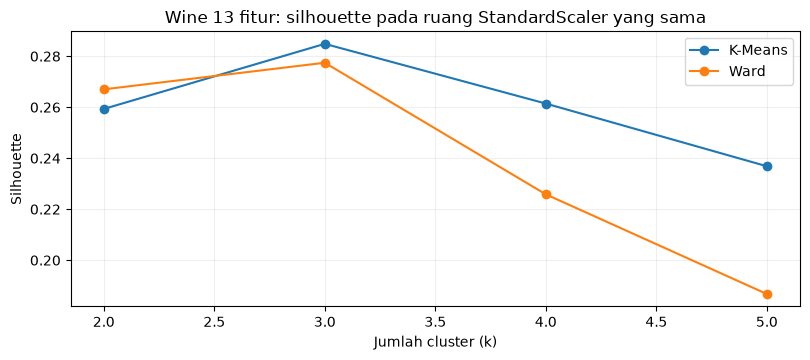

In [7]:
for k in [2,3,4,5]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'B1_{method.replace("-","")}_k{k}',X_std,method,k,X_eval=X_std,notes='Wine standardized, 13 fitur')
baseline_table=pd.DataFrame(EXPERIMENTS)
display(baseline_table[['run','model','k','silhouette_common','DBI_common','min_size','max_size']].round(3))
fig,ax=plt.subplots(figsize=(8.2,3.7))
for method,sub in baseline_table.groupby('model'):
    sub=sub.sort_values('k');ax.plot(sub.k,sub.silhouette_common,marker='o',label=method)
ax.set(title='Wine 13 fitur: silhouette pada ruang StandardScaler yang sama',xlabel='Jumlah cluster (k)',ylabel='Silhouette')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

### P3-B. Dendrogram: kapan Hierarchical punya nilai tambah?
**JALANKAN:** dendrogram Wine standardized. Untuk keterbacaan, grafik menggunakan `truncate_mode='lastp'`; **semua 178 sampel tetap dipakai** untuk membentuk linkage. Cabang pada tampilan terpotong adalah agregasi, bukan observasi asli.

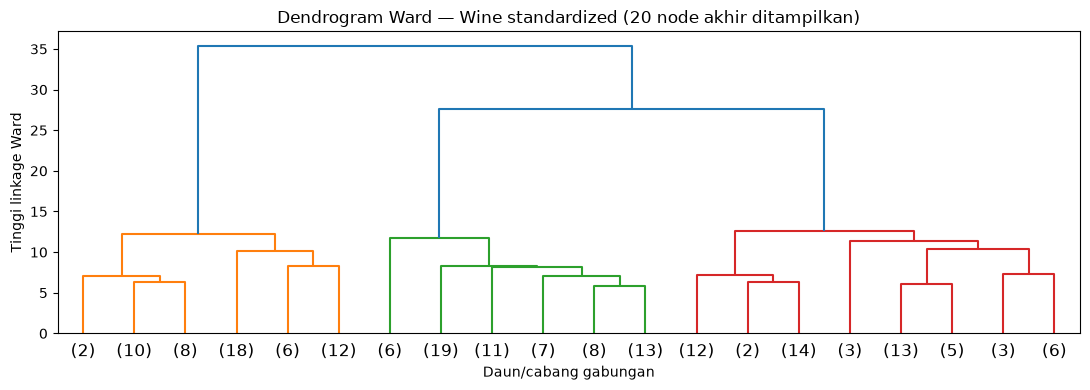

In [8]:
Z_ward = linkage(X_std, method='ward', metric='euclidean')
fig,ax=plt.subplots(figsize=(11,4))
dendrogram(Z_ward,truncate_mode='lastp',p=20,show_leaf_counts=True,ax=ax)
ax.set(title='Dendrogram Ward — Wine standardized (20 node akhir ditampilkan)',xlabel='Daun/cabang gabungan',ylabel='Tinggi linkage Ward')
plt.tight_layout();plt.show()

**✍️ JAWABAN ANDA — P3 (minimal 100 kata).** Pilih satu k yang menurut Anda layak (bukan otomatis yang skor maksimum). Sebutkan **dua angka** pendukung dan **satu alasan kegunaan dendrogram/centroid**. Jelaskan apakah hasil audit P2 sudah cukup untuk memastikan algoritma terbaik.

**Jawab di sini:** Saya memilih **k = 3**. Pada ruang X_std yang sama, k = 3 memberi silhouette tertinggi untuk kedua metode (**Ward 0.277; K-Means 0.285**) dan DBI terendah untuk K-Means (**1.389**). Ward k = 2 sebenarnya punya DBI sedikit lebih kecil (1.412 vs 1.419), sehingga dua metrik tidak sepenuhnya sepakat. Meski begitu, k = 2 menghasilkan cluster timpang (56 vs 122) yang kemungkinan menggabungkan dua kelompok berbeda. Pada k = 3 ukuran cluster seimbang (Ward 56/58/64, K-Means 51/62/65), sedangkan k = 4–5 menurunkan silhouette (K-Means 0.261 → 0.237, Ward 0.226 → 0.187) dan menaikkan DBI (> 1.6).

Dendrogram memberi bukti tambahan yang tidak bergantung pada satu angka. Tinggi merge naik perlahan sampai sekitar 12.6, lalu melompat ke sekitar 27.7 dan 35.4. Memotong di celah besar itu menghasilkan tepat tiga cabang, jadi pilihan k = 3 terlihat secara visual dan bukan hanya dari skor maksimum. Sebaliknya, centroid K-Means memberi profil rata-rata yang bisa langsung dibaca dan dapat dipakai untuk menempatkan sampel baru.

Audit P2 **belum cukup** untuk memastikan algoritma terbaik. P2 hanya menunjukkan kelayakan (data bersih, wajib scaling, ada redundansi), sementara selisih Ward vs K-Means di k = 3 sangat kecil (0.008 silhouette). Kita masih perlu ablation (P4) dan uji sensitivitas data (P5) untuk melihat metode mana yang lebih stabil.

## P4 — Ablation: uji pengaruh materi preprocessing dan feature engineering P1–P7

**Aturan satu-perubahan:** bandingkan satu keputusan yang diubah, dengan metode dan k tetap. Gunakan `k=3` sebagai titik awal **untuk belajar mekanisme**, bukan klaim jumlah cluster optimal.

Untuk membandingkan representasi berbeda, seluruh partisi dievaluasi pada `X_std` yang sama (`silhouette_common`, `DBI_common`). Dengan ini, kita menilai apakah partisi tetap masuk akal dalam ruang 13 fitur standar. Tampilkan juga skor ruang fit untuk mempelajari sensitivitas metrik.

### P4-A. Ablation scaling: raw vs standard vs robust, Ward dan K-Means
**JALANKAN:** dataset sama; yang berubah hanya cara scaling. Jelaskan mengapa silhouette di ruang mentah bisa tinggi meskipun fitur berunit besar mendominasi.

In [9]:
X_robust = RobustScaler().fit_transform(X_raw)
for method in ['Ward','K-Means']:
    for tag,Xv in [('RAW',X_raw.to_numpy()),('STD',X_std),('ROBUST',X_robust)]:
        evaluate_run(f'P4_{method.replace("-","")}_{tag}', Xv, method, 3, X_eval=X_std,
                     notes=f'pengaruh scaling: {tag}')
rows_scaling = pd.DataFrame(EXPERIMENTS).query("run.str.startswith('P4_')",engine='python')
display(rows_scaling[['run','silhouette_common','silhouette_fit_space','DBI_common','min_size']].round(3))

,run,silhouette_common,silhouette_fit_space,DBI_common,min_size
8,P4_Ward_RAW,0.106,0.564,3.427,48
9,P4_Ward_STD,0.277,0.277,1.419,56
10,P4_Ward_ROBUST,0.275,0.256,1.389,55
11,P4_KMeans_RAW,0.108,0.571,3.364,47
12,P4_KMeans_STD,0.285,0.285,1.389,51
13,P4_KMeans_ROBUST,0.280,0.264,1.391,49


### P4-B. Ablation *feature selection*: menghapus fitur sangat berkorelasi
**JALANKAN:** fitur diseleksi dengan filter korelasi absolut `>0.80`; angka ambang dipilih sebagai contoh, **bukan aturan universal**. Dalam clustering, fitur dengan korelasi tinggi bisa tetap punya arti domain; selalu catat fitur yang dibuang.

In [10]:
THRESHOLD_R = 0.80
corr_abs = X_raw.corr().abs()
upper_only = corr_abs.where(np.triu(np.ones(corr_abs.shape),k=1).astype(bool))
to_drop = [c for c in upper_only.columns if (upper_only[c] > THRESHOLD_R).any()]
cols_keep = [c for c in X_raw.columns if c not in to_drop]
X_select = StandardScaler().fit_transform(X_raw[cols_keep])
print('Fitur dibuang:', to_drop, '| jumlah tersisa:', len(cols_keep), 'dari 13')
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_SELECT', X_select,method,3,X_eval=X_std,notes='Corr filter > .80')

Fitur dibuang: ['flavanoids'] | jumlah tersisa: 12 dari 13


### P4-C. Ablation PCA 90% explained variance
**JALANKAN:** standardisasi dilanjutkan PCA; cek berapa komponen yang diperlukan untuk mencapai minimal 90% variance. PCA adalah transformasi gabungan fitur, bukan pemilihan kolom asli; skor ruang PCA tidak sepenuhnya sebanding dengan skor ruang standar, maka gunakan *common evaluation space*.

PCA: dimensi 13 → 8 | retained cumulative EVR: 0.9202


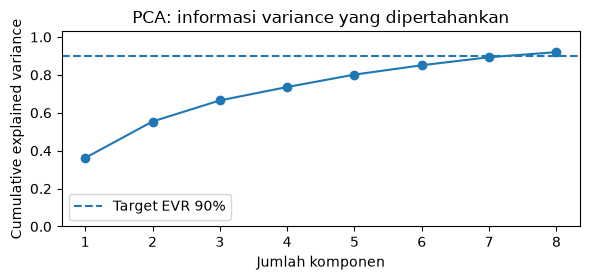

In [11]:
pca = PCA(n_components=0.90, svd_solver='full')
X_pca = pca.fit_transform(X_std)
print('PCA: dimensi', X_std.shape[1], '→', X_pca.shape[1],
      '| retained cumulative EVR:',round(float(pca.explained_variance_ratio_.sum()),4))
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_PCA90', X_pca, method,3,X_eval=X_std,notes='StandardScaler + PCA 90%')
fig,ax=plt.subplots(figsize=(6,2.9))
ax.plot(range(1,X_pca.shape[1]+1),np.cumsum(pca.explained_variance_ratio_),marker='o')
ax.axhline(.90,ls='--',label='Target EVR 90%')
ax.set(title='PCA: informasi variance yang dipertahankan',xlabel='Jumlah komponen',ylabel='Cumulative explained variance')
ax.set_ylim(0,1.03);ax.legend();plt.tight_layout();plt.show()

### P4-D. Ablation nilai ekstrem: clip berbasis IQR (analisis sensitivitas)
**JALANKAN:** membatasi nilai di luar 1,5×IQR sebagai **eksperimen sensitivitas**, bukan keputusan otomatis bahwa nilai ekstrem salah. Jangan mengklaim setiap perubahan skor adalah perbaikan yang sah tanpa alasan domain.

In [12]:
low, high = q1-1.5*iqr, q3+1.5*iqr
X_clip = X_raw.clip(lower=low,upper=high,axis='columns')
changed_cells = int((X_clip != X_raw).sum().sum())
X_clip_std=StandardScaler().fit_transform(X_clip)
print('Nilai sel yang berubah akibat IQR clipping:',changed_cells)
for method in ['Ward','K-Means']:
    evaluate_run(f'P4_{method.replace("-","")}_CLIP', X_clip_std,method,3,X_eval=X_std,notes='IQR clip pada fitur asli')

Nilai sel yang berubah akibat IQR clipping: 21


### P4-E. Tabel percobaan terkendali
**JALANKAN:** bandingkan **B1 k=3** dengan P4 scaling, selection, PCA, dan clipping. **JAWAB:** fitur/dimensi apa yang berubah? Apakah nilai *common* dan *fit* bergerak searah? Mengapa “skor lebih tinggi” tidak otomatis berarti metode lebih baik?

In [13]:
all_results = pd.DataFrame(EXPERIMENTS)
compare_p4=all_results[(all_results.k.eq(3)) & ((all_results.run.str.startswith('B1_')) | (all_results.run.str.startswith('P4_')))]
display(compare_p4[['run','model','fit_dim','silhouette_common','DBI_common',
                    'silhouette_fit_space','min_size','size_pattern']].round(3))

,run,model,fit_dim,silhouette_common,DBI_common,silhouette_fit_space,min_size,size_pattern
2,B1_Ward_k3,Ward,13,0.277,1.419,0.277,56,"[56, 58, 64]"
3,B1_KMeans_k3,K-Means,13,0.285,1.389,0.285,51,"[51, 62, 65]"
8,P4_Ward_RAW,Ward,13,0.106,3.427,0.564,48,"[48, 58, 72]"
9,P4_Ward_STD,Ward,13,0.277,1.419,0.277,56,"[56, 58, 64]"
10,P4_Ward_ROBUST,Ward,13,0.275,1.389,0.256,55,"[55, 56, 67]"
11,P4_KMeans_RAW,K-Means,13,0.108,3.364,0.571,47,"[47, 62, 69]"
12,P4_KMeans_STD,K-Means,13,0.285,1.389,0.285,51,"[51, 62, 65]"
13,P4_KMeans_ROBUST,K-Means,13,0.280,1.391,0.264,49,"[49, 63, 66]"
14,P4_Ward_SELECT,Ward,12,0.270,1.407,0.260,56,"[56, 59, 63]"
15,P4_KMeans_SELECT,K-Means,12,0.284,1.394,0.277,51,"[51, 63, 64]"


**✍️ JAWABAN ANDA — P4.** Isi **minimal tiga** pasangan ablation dan satu kalimat sebab-akibat yang masuk akal. Klaim “PCA memperbaiki model karena skor naik” belum cukup; jelaskan pengurangan dimensi dan risiko hilangnya informasi.

| Dua run dibandingkan | Hanya keputusan apa yang berubah? | Perubahan metrik (angka) | Penjelasan + trade-off |
|---|---|---|---|
| `P4_KMeans_STD` vs `P4_KMeans_RAW` | Scaling: StandardScaler → tanpa scaling | silhouette_common 0.285 → **0.108**; DBI_common 1.389 → **3.364**; tetapi silhouette_fit_space RAW = **0.571** | Tanpa scaling, jarak hampir hanya ditentukan `proline` (rentang 1402). Di ruang mentah partisi tampak terpisah (0.571) karena data dibelah di satu sumbu besar, tetapi dinilai pada 13 fitur setara partisinya buruk. Skor *fit* yang tinggi menyesatkan |
| `P4_Ward_STD` vs `P4_Ward_ROBUST` | Scaling: StandardScaler → RobustScaler (median/IQR) | silhouette_common 0.277 → 0.275; DBI_common 1.419 → **1.389**; ukuran 56/58/64 → 55/56/67 | Perubahan sangat kecil. Outlier Wine sedikit (≤4 per fitur), jadi RobustScaler tidak memberi keuntungan berarti. Hasil Ward cukup stabil terhadap pilihan scaler |
| `P4_Ward_STD` vs `P4_Ward_SELECT` | Fitur: 13 → 12 (buang `flavanoids`, \|r\| = 0.865 dengan `total_phenols`) | silhouette_common 0.277 → **0.270**; DBI 1.419 → 1.407; K-Means 0.285 → 0.284 | Menghapus satu fitur redundan hampir tidak mengubah partisi. Namun `flavanoids` punya makna kimia sendiri, dan membuangnya sedikit menurunkan silhouette Ward. Tidak ada alasan kuat untuk membuangnya |
| `P4_Ward_STD` vs `P4_Ward_PCA90` | Representasi: 13 fitur → 8 komponen PCA (EVR 0.920) | silhouette_fit_space 0.277 → **0.305**, tetapi silhouette_common 0.277 → **0.275**; DBI_common 1.419 → 1.389 | Skor *fit* naik karena 8% varians (noise/detail) dibuang dan dimensi lebih sedikit. Di ruang evaluasi bersama partisinya hampir sama. Jadi PCA **tidak** terbukti memperbaiki cluster; komponennya juga lebih sulit ditafsirkan daripada fitur asli |
| `P4_Ward_STD` vs `P4_Ward_CLIP` | Clipping 21 sel ke batas 1.5×IQR | silhouette_common 0.277 → 0.279; DBI 1.419 → 1.409; K-Means tidak berubah (0.285, 51/62/65) | Efeknya kecil karena hanya 21 dari 2314 sel (≈0.9%) yang berubah. Clipping tanpa alasan domain berisiko menghapus variasi asli |

**Jawab di sini:** Ablation yang paling menentukan adalah **scaling**. Tanpa scaling, silhouette_common jatuh ke ≈0.11 dan DBI naik ke ≈3.4, padahal skor di ruang fit justru tertinggi (0.56–0.57). Ini contoh bahwa “skor lebih tinggi” bisa menipu jika ruang evaluasinya berbeda: skor fit RAW tinggi karena pemisahan satu dimensi (`proline`), bukan karena struktur 13 fitur. Ablation lain (robust, select, PCA, clip) hanya menggeser silhouette_common sekitar ±0.01, sehingga perbedaannya lebih kecil dari yang layak diklaim sebagai perbaikan. K-Means hampir tidak berubah di semua ablation, sedangkan Ward sedikit lebih sensitif (0.270–0.279). Skor *common* dan *fit* **tidak selalu bergerak searah** (lihat RAW dan PCA90), jadi keputusan diambil dari *common evaluation space*, kesederhanaan, dan kemudahan interpretasi, bukan dari angka fit tertinggi.

## P5 — Bukti dari P4–P5: apa akibat **missing, duplikasi, dan outlier**?

Wine asli tidak memiliki missing/duplikasi persis. Karena itu kita membentuk **SALINAN TERGANGGU secara sengaja**. Baris asli tidak diubah; simulasi ini **bukan karakteristik Wine asli**. Tujuannya menunjukkan prosedur cleaning dan kualitas data memengaruhi hasil clustering.

**Keputusan penting:** model clustering memerlukan matriks numerik tanpa NaN. Nilai yang hilang harus ditangani; duplikasi dapat mengubah bobot pola; outlier dapat menggeser centroid atau mengubah urutan merge. Jangan menilai preprocessing yang dipilih berdasarkan label asli Wine.

In [14]:
X_dirty = X_raw.copy()
# Sengaja menaruh missing pada beberapa sel, menduplikasi beberapa baris,
# dan membuat 1 nilai proline ekstrem; semua ini simulasi pembelajaran.
missing_rng = np.random.default_rng(SEED+11)
missing_pairs = missing_rng.choice(len(X_dirty)*3, size=20, replace=False)
for idx in missing_pairs:
    r, cidx = divmod(int(idx), 3)
    X_dirty.iloc[r, cidx] = np.nan
outlier_row=17
original_proline=float(X_dirty.iloc[outlier_row]["proline"])
X_dirty.loc[outlier_row, 'proline'] = original_proline*8
X_dirty=pd.concat([X_dirty, X_dirty.loc[[0,2,59,60]]],ignore_index=True)
print('Wine ASLI:',X_raw.shape, 'missing',int(X_raw.isna().sum().sum()),'duplikat',int(X_raw.duplicated().sum()))
print('Wine SALINAN TERGANGGU:',X_dirty.shape,'missing',int(X_dirty.isna().sum().sum()),
      'duplikat',int(X_dirty.duplicated().sum()))
print('Outlier buatan: proline row 17 sebelum',original_proline,'sesudah',original_proline*8)

Wine ASLI: (178, 13) missing 0 duplikat 0
Wine SALINAN TERGANGGU: (182, 13) missing 20 duplikat 4
Outlier buatan: proline row 17 sebelum 1130.0 sesudah 9040.0


### P5-A. Bandingkan dua penanganan: naive vs audit + cleaning
**PENTING:** `naive` memakai imputasi mean dan tetap membiarkan duplikasi serta outlier buatan. `cleaned` memakai median, menghapus duplikasi persis sebelum fit scaler, lalu clipping ringan dari kuantil 1%–99% sebagai **contoh kebijakan simulasi**, bukan aturan baku. Karena penghapusan duplikasi mengubah n, metrik antar-output tidak apple-to-apple. Untuk **bukti perbandingan adil**, model fit pada versi yang sudah dibersihkan lalu **diproyeksikan kembali pada 178 baris bersih asli** tidak trivial untuk Ward yang tidak punya `predict`. Karena itu bagian ini fokus pada perubahan hasil, jumlah anggota, dan audit kualitas; **jangan membandingkan angka antar-n secara langsung untuk menyatakan menang**.

In [15]:
X_dirty_naive=SimpleImputer(strategy='mean').fit_transform(X_dirty)
X_dirty_naive_std=StandardScaler().fit_transform(X_dirty_naive)
X_dirty_dedup=X_dirty.drop_duplicates().copy()
X_dirty_median=pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_dirty_dedup),columns=X_raw.columns)
ql=X_dirty_median.quantile(.01); qh=X_dirty_median.quantile(.99)
X_dirty_clean=X_dirty_median.clip(lower=ql,upper=qh,axis='columns')
X_dirty_clean_std=StandardScaler().fit_transform(X_dirty_clean)
for tag,Xv in [('DIRTY_MEAN_NO_CLEAN',X_dirty_naive_std),('CLEAN_MEDIAN_CLIP',X_dirty_clean_std)]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'P5_{method.replace("-","")}_{tag}',Xv,method,3,X_eval=Xv,
                     notes='DATA SIMULASI TERGANGGU; n bisa berubah')
P5_table=pd.DataFrame(EXPERIMENTS)
display(P5_table[P5_table.run.str.startswith('P5_')][['run','n','silhouette_fit_space','DBI_common','min_size','max_size']].round(3))

,run,n,silhouette_fit_space,DBI_common,min_size,max_size
20,P5_Ward_DIRTY_MEAN_NO_CLEAN,182,0.252,1.507,51,74
21,P5_KMeans_DIRTY_MEAN_NO_CLEAN,182,0.261,1.463,50,73
22,P5_Ward_CLEAN_MEDIAN_CLIP,178,0.280,1.403,55,62
23,P5_KMeans_CLEAN_MEDIAN_CLIP,178,0.289,1.363,50,68


### P5-B. **Ablation yang lebih adil:** satu masalah data dalam satu waktu, jumlah baris tetap 178

**JALANKAN:** supaya perubahan bisa diatribusikan lebih jelas, buat tiga dataset dengan baris sama: (i) **original**, (ii) **missing 20 sel lalu median imputation**, (iii) **satu outlier buatan pada `proline`**. Bandingkan partisi pada `X_std` asli yang **sama**. Ini mengisolasi dampak yang lebih spesifik daripada P5-A.

In [16]:
X_miss_only=X_raw.copy()
for idx in missing_pairs:
    r,cidx=divmod(int(idx),3)
    X_miss_only.iloc[r,cidx]=np.nan
X_miss_imp=SimpleImputer(strategy='median').fit_transform(X_miss_only)
X_miss_std=StandardScaler().fit_transform(X_miss_imp)
X_outlier_only=X_raw.copy()
X_outlier_only.loc[outlier_row,'proline']=original_proline*8
X_outlier_std=StandardScaler().fit_transform(X_outlier_only)
for tag,arr in [('ORIGINAL',X_std),('MISSING_MEDIAN',X_miss_std),('OUTLIER_X8',X_outlier_std)]:
    for method in ['Ward','K-Means']:
        evaluate_run(f'P5_ISOLATED_{method.replace("-","")}_{tag}',arr,method,3,X_eval=X_std,
                     notes='n=178, data simulasi, evaluasi X_std original')
isolated=pd.DataFrame(EXPERIMENTS)
display(isolated[isolated.run.str.startswith('P5_ISOLATED')][['run','n','silhouette_common',
           'DBI_common','SSE_common','min_size']].round(3))

,run,n,silhouette_common,DBI_common,SSE_common,min_size
24,P5_ISOLATED_Ward_ORIGINAL,178,0.277,1.419,1305.049,56
25,P5_ISOLATED_KMeans_ORIGINAL,178,0.285,1.389,1277.928,51
26,P5_ISOLATED_Ward_MISSING_MEDIAN,178,0.277,1.405,1294.071,52
27,P5_ISOLATED_KMeans_MISSING_MEDIAN,178,0.284,1.398,1283.557,50
28,P5_ISOLATED_Ward_OUTLIER_X8,178,0.260,1.439,1324.403,56
29,P5_ISOLATED_KMeans_OUTLIER_X8,178,0.278,1.400,1284.059,51


**✍️ JAWABAN ANDA — P5.** Mengapa missing harus ditangani sebelum Euclidean? Mengapa duplikasi dapat memengaruhi pusat K-Means? Apakah nilai sangat besar pasti salah? Mengapa angka skor dari `n` berbeda **tidak dapat** dipakai membuktikan hasil cleaning lebih baik? Berikan sedikitnya satu bukti angka dari output.

**Jawab di sini:** *(Semua kerusakan di bagian ini adalah **SIMULASI** pada salinan data, bukan karakteristik Wine asli yang punya 0 missing dan 0 duplikat.)*

- **Missing.** Jarak Euclidean membutuhkan selisih di setiap dimensi, sedangkan NaN membuat jarak tidak terdefinisi. `AgglomerativeClustering`/`KMeans` juga menolak input NaN, jadi missing harus diimputasi atau barisnya dibuang terlebih dahulu. Pada P5-B, 20 sel missing yang diisi median hanya sedikit mengubah hasil: Ward silhouette_common tetap 0.277 dengan DBI 1.419 → 1.405, sedangkan K-Means 0.285 → 0.284. Dampaknya kecil karena 20 sel hanya ≈0.9% data dan median mewakili nilai tengah.
- **Duplikasi.** Centroid K-Means adalah rata-rata anggota. Baris yang muncul dua kali (di sini baris 0, 2, 59, 60) mendapat bobot ganda dan menarik centroid ke arahnya. Ward juga menghitung SSE dari jumlah titik, sehingga duplikat menambah bobot pola tersebut. Pada P5-A, data naif memiliki n = 182 dengan 4 duplikat.
- **Nilai sangat besar belum tentu salah.** Wine asli memiliki `proline` maksimum 1680 yang masih wajar secara kimia. Nilai 9040 (8 × 1130) pada baris 17 sengaja dibuat, dan dalam kasus nyata perlu dicek ke sumber atau domain sebelum diputuskan sebagai kesalahan. Dampaknya terlihat jelas: outlier tunggal ini menurunkan silhouette_common **Ward 0.277 → 0.260** (SSE_common 1305.0 → 1324.4), sementara K-Means hanya 0.285 → 0.278. Outlier ekstrem membuat standardisasi `proline` menyempit untuk 177 sampel lain, sehingga struktur yang dibentuk fitur itu ikut berubah.
- **n berbeda tidak sebanding.** P5-A membandingkan n = 182 (naif) dengan n = 178 (cleaned). Data, scaler, dan ruang evaluasinya berbeda, dan clipping 1%–99% juga mengecilkan sebaran. Kenaikan silhouette_fit_space 0.252 → 0.280 (Ward) dan 0.261 → 0.289 (K-Means) bisa terjadi hanya karena titik ekstrem dipangkas dan duplikat dihapus, bukan bukti bahwa partisinya lebih benar. Bukti yang lebih adil ada di P5-B: n tetap 178, satu masalah per run, dan evaluasi pada X_std asli yang sama.

## P6 — Dua kondisi data: kapan Ward, kapan K-Means?

### Kasus A — Wine asli, 178 × 13, tujuan memahami struktur bertingkat

**EDA berkata:** dataset relatif terkelola, fitur numerik, skala sangat berbeda, ada beberapa korelasi tinggi, dan tujuan *eksplorasi hierarki* dapat dibantu dendrogram. Karena itu **Ward layak diuji**. Namun jika yang dicari hanya segmen kompak, K-Means juga layak. Tabel P3 menentukan apakah ada trade-off kualitas numerik dengan nilai dendrogram.

### Kasus B — 3.000 titik **SINTETIS**, kelompok kompak, tujuan segmentasi praktis

Dataset di bawah **bukan data riil** dan tidak digunakan untuk klaim tentang Wine. Fungsi `make_blobs` hanya menghasilkan dua fitur numerik dan kelompok kompak supaya mudah memahami apakah metode centroid memiliki alasan desain yang kuat. Parameter `centers` diketahui oleh pembuat contoh, tetapi label generator **tidak** dimasukkan ke model.

**JALANKAN:** EDA singkat data besar, uji K-Means semua baris, perkirakan pertumbuhan kebutuhan memori matriks jarak. Untuk benchmark adil kualitas K-Means vs Ward, gunakan **subsample yang sama** (`n=450`) dan k yang sama. Keputusan skala besar berlandaskan kebutuhan proses, biaya, dan sifat data—bukan klaim bahwa Ward tidak bisa dijalankan.

EDA data sintetis: (3000, 2) missing: 0 duplicate: 0


,fitur_x,fitur_y
min,-10.44,-7.34
median,1.03,-0.89
std,5.07,3.54
max,12.37,7.86


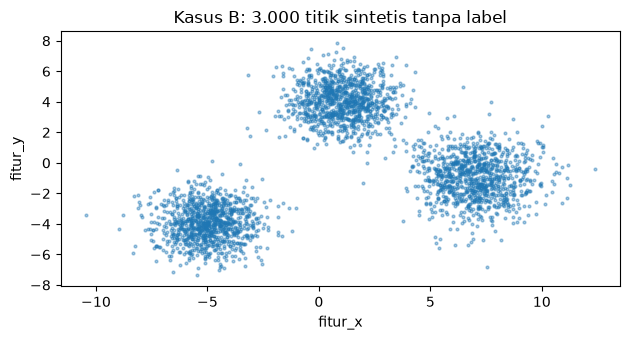

n=  178 | n×n float64 kira-kira     0.2 MB | condensed distances     0.1 MB
n=  450 | n×n float64 kira-kira     1.5 MB | condensed distances     0.8 MB
n= 3000 | n×n float64 kira-kira    68.7 MB | condensed distances    34.3 MB
n=10000 | n×n float64 kira-kira   762.9 MB | condensed distances   381.4 MB
Estimasi memori HANYA matriks jarak: bukan total memory atau jaminan alokasi dari library.


In [17]:
X_big, _labels_generator_dilarang = make_blobs(
    n_samples=3000, centers=[[-5,-4],[1,4],[7,-1]], cluster_std=[1.15,1.2,1.4],
    random_state=SEED, n_features=2)
# Label generator tidak digunakan untuk fit atau memilih hasil.
big = pd.DataFrame(X_big,columns=['fitur_x','fitur_y'])
print('EDA data sintetis:',big.shape, 'missing:',big.isna().sum().sum(),
      'duplicate:',big.duplicated().sum())
display(big.agg(['min','median','std','max']).round(2))
fig,ax=plt.subplots(figsize=(6.4,3.5))
ax.scatter(big.fitur_x,big.fitur_y,s=4,alpha=.4)
ax.set(title='Kasus B: 3.000 titik sintetis tanpa label',xlabel='fitur_x',ylabel='fitur_y');plt.tight_layout();plt.show()
for n in [178, 450, 3000, 10000]:
    full_mb=(n*n*8)/(1024*1024)
    condensed_mb=(n*(n-1)/2*8)/(1024*1024)
    print(f'n={n:5d} | n×n float64 kira-kira {full_mb:7.1f} MB | condensed distances {condensed_mb:7.1f} MB')
print('Estimasi memori HANYA matriks jarak: bukan total memory atau jaminan alokasi dari library.')

In [18]:
X_big_std=StandardScaler().fit_transform(big)
# n=450 sama untuk benchmark kualitas (menggunakan random sample index yang pasti)
idx_sampel=np.random.default_rng(SEED).choice(len(X_big_std),size=450,replace=False)
X_sample=X_big_std[idx_sampel]
for method in ['Ward','K-Means']:
    evaluate_run(f'P6_SMALL_{method.replace("-","")}',X_sample,method,3,X_eval=X_sample,
                 notes='perbandingan n=450 data sintetis dengan ruang/k sama')
# n=3000: K-Means dipakai karena tujuan partitioning praktis; bukan mengklaim Ward mustahil
large_record=evaluate_run('P6_LARGE_KMeans',X_big_std,'K-Means',3,X_eval=X_big_std,
               notes='segmen kompak n=3000, k ditentukan; Ward tidak wajib pada data besar')
P6_table=pd.DataFrame(EXPERIMENTS)
display(P6_table[P6_table.run.str.startswith('P6_')][['run','n','silhouette_common',
          'DBI_common','min_size','fit_seconds']].round(3))

,run,n,silhouette_common,DBI_common,min_size,fit_seconds
30,P6_SMALL_Ward,450,0.715,0.406,137,0.003
31,P6_SMALL_KMeans,450,0.715,0.405,137,0.116
32,P6_LARGE_KMeans,3000,0.723,0.397,994,0.045


**✍️ JAWABAN ANDA — P6.** Isilah tabel keputusan berikut dengan **data dari output**, bukan kesimpulan umum tanpa bukti.

| Aspek | Kasus A: Wine nyata | Kasus B: data sintetis 3.000 titik |
|---|---|---|
| Tujuan analisis | Eksplorasi: memahami apakah ada kelompok kimia anggur dan bagaimana kelompok itu tersusun (profil yang dapat ditafsirkan) | Segmentasi praktis: membagi banyak titik ke k segmen kompak dan menempatkan titik baru ke segmen |
| EDA: jumlah & jenis fitur | 178 × 13 numerik; 0 missing/duplikat; skala timpang (rasio rentang 2645×); korelasi sampai 0.865 | 3000 × 2 numerik; 0 missing/duplikat; std fitur_x 5.07, fitur_y 3.54 (skala setara); scatter menunjukkan 3 gumpalan terpisah |
| Bukti struktur/kepraktisan | Silhouette k = 3 sedang (0.277–0.285), jadi cluster tidak terpisah tegas. Dendrogram menunjukkan lompatan merge ±12.6 → ±27.7 yang mendukung 3 cabang | Struktur kompak dan jelas: silhouette n = 450 = 0.715, n = 3000 = 0.723; DBI ≈ 0.40 |
| Biaya komputasi & manfaat dendrogram | Matriks jarak ≈0.2 MB (n×n), Ward murah. Dendrogram bernilai karena struktur tidak tegas dan k perlu dijustifikasi | Matriks jarak n×n ≈68.7 MB untuk 3000 (≈763 MB untuk 10.000), tumbuh O(n²). Dendrogram 3000 daun sulit dibaca dan tidak dibutuhkan karena 3 gumpalan sudah jelas |
| Nilai hasil pembanding adil | k = 3, X_std sama: Ward 0.277 / DBI 1.419; K-Means 0.285 / DBI 1.389 (selisih kecil) | n = 450 sama, k = 3: Ward 0.715 / DBI 0.406; K-Means 0.715 / DBI 0.405, praktis identik. K-Means penuh n = 3000 hanya 0.031 detik |
| **Metode pilihan sementara + alasan** | **K-Means k = 3**, didukung dendrogram Ward sebagai validasi. Skor common sedikit lebih baik, paling stabil di ablation dan outlier, dan centroid memberi profil yang mudah ditafsirkan. Ward tetap wajar jika fokusnya hierarki | **K-Means k = 3**. Kualitas setara dengan Ward pada subsampel adil, tetapi K-Means memberi centroid untuk `predict` titik baru, tidak perlu menyimpan matriks jarak O(n²), dan tujuan tidak menuntut hierarki |

**Catatan:** pilihan Kasus B **bukan** karena “data besar → K-Means”. Pada n = 450 yang adil, kualitas keduanya sama (0.715), sehingga yang membedakan adalah kebutuhan centroid untuk segmentasi, tidak adanya kebutuhan hierarki, dan biaya memori. Untuk Wine, Ward juga **tidak** otomatis menang walaupun datanya kecil: K-Means sedikit lebih baik dan lebih stabil.

**P6-C (make_moons):** dengan k = 2, Ward maupun K-Means memotong dua bulan sabit dengan garis yang kurang lebih lurus, sehingga ujung tiap bulan masuk ke kelompok yang salah secara bentuk. Keduanya mengasumsikan cluster kompak/konveks, jadi data berbentuk melengkung membutuhkan metode berbasis kepadatan seperti DBSCAN (P9).

### P6-C (opsional) — Ketika keduanya belum tentu cocok
**JALANKAN bila waktu cukup:** data bulan sabit sintetis (*make_moons*). Clustering yang hanya mencari kelompok kompak atau menggabungkan berdasarkan Ward mungkin tidak mengikuti bentuk melengkung. Ini pengantar alasan mempelajari **DBSCAN pada Pertemuan 9**. Jangan memaksakan “hierarchical vs K-Means” jika karakter data mengisyaratkan kebutuhan metode lain.

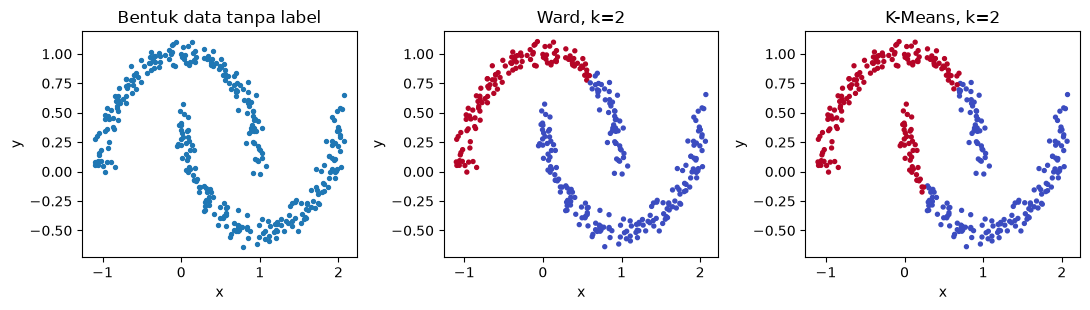

In [19]:
X_moon,_ = make_moons(n_samples=350,noise=0.06,random_state=SEED)
fig,axes=plt.subplots(1,3,figsize=(11,3.2))
axes[0].scatter(X_moon[:,0],X_moon[:,1],s=8);axes[0].set_title('Bentuk data tanpa label')
for ax,met in zip(axes[1:],['Ward','K-Means']):
    if met=='Ward': labs=AgglomerativeClustering(n_clusters=2,linkage='ward').fit_predict(X_moon)
    else: labs=KMeans(n_clusters=2,n_init=20,random_state=SEED).fit_predict(X_moon)
    ax.scatter(X_moon[:,0],X_moon[:,1],c=labs,s=8,cmap='coolwarm')
    ax.set_title(f'{met}, k=2')
for ax in axes: ax.set_xlabel('x');ax.set_ylabel('y')
plt.tight_layout();plt.show()

## P7 — Keputusan akhir, interpretasi cluster, dan portofolio

### P7-A. Tentukan konfigurasi final berdasarkan **bukti**
**WAJIB:** Pilih satu dari Ward/K-Means untuk Wine. Ubah nilai konfigurasi jika beralasan. Anda boleh memilih metode yang tidak paling tinggi silhouette-nya asalkan pilihan bermotivasi, transparan, dan mempertimbangkan kebutuhan pengguna.

**EDIT BLOK INI:** pilih kombinasi yang benar-benar Anda ujikan. Opsinya: `scaler = 'StandardScaler' / 'RobustScaler' / 'NONE'`; `representation = 'ALL' / 'CORR' / 'PCA90'`; `clip_iqr = True/False`; model `Ward`/`K-Means`, `k=2–5`. Sel final akan **benar-benar membangun transformasi pilihan Anda**, bukan hanya menuliskan namanya. `PCA90` harus disertai scaling agar variasi tidak dikuasai satuan fitur.

In [20]:
FINAL_CONFIG = {
    'dataset': 'Wine asli; 178 observasi; 13 fitur numerik; tanpa label',
    'scaler':'StandardScaler',  # EDIT: StandardScaler / RobustScaler / NONE
    'representation':'ALL',   # EDIT: ALL / CORR / PCA90
    'clip_iqr':False,         # EDIT: True atau False
    'method':'K-Means',       # EDIT: Ward atau K-Means
    'k':3,                    # EDIT: 2,3,4,5
    'seed': SEED,
    'reason':('EDA: 0 missing/duplikat, rasio rentang 2645x -> wajib StandardScaler; '
              'P3: k=3 silhouette_common tertinggi (KMeans 0.285, Ward 0.277), DBI KMeans 1.389, '
              'dendrogram Ward melompat 12.6->27.7 mendukung 3 cabang; '
              'P4/P5: KMeans paling stabil (robust/select/PCA/clip 0.280-0.285; outlier x8 0.278 vs Ward 0.260); '
              'ALL dipertahankan karena SELECT/PCA tidak memperbaiki skor common dan mengurangi interpretabilitas'),  # WAJIB EDIT
}
assert FINAL_CONFIG['method'] in ['Ward','K-Means']
assert FINAL_CONFIG['k'] in [2,3,4,5]
assert FINAL_CONFIG['scaler'] in ['StandardScaler','RobustScaler','NONE']
assert FINAL_CONFIG['representation'] in ['ALL','CORR','PCA90']
base_final=X_raw.copy()
if FINAL_CONFIG['clip_iqr']:
    base_final=base_final.clip(lower=low,upper=high,axis='columns')
if FINAL_CONFIG['representation']=='CORR':
    base_final=base_final[cols_keep]
if FINAL_CONFIG['scaler']=='StandardScaler':
    X_final_fit=StandardScaler().fit_transform(base_final)
elif FINAL_CONFIG['scaler']=='RobustScaler':
    X_final_fit=RobustScaler().fit_transform(base_final)
else:
    X_final_fit=base_final.to_numpy()
if FINAL_CONFIG['representation']=='PCA90':
    assert FINAL_CONFIG['scaler']!='NONE', 'PCA90 perlu scaling pada praktikum ini.'
    X_final_fit=PCA(n_components=.90,svd_solver='full').fit_transform(X_final_fit)
if FINAL_CONFIG['method']=='Ward':
    final_labels=AgglomerativeClustering(n_clusters=FINAL_CONFIG['k'],linkage='ward').fit_predict(X_final_fit)
else:
    final_labels=KMeans(n_clusters=FINAL_CONFIG['k'],n_init=20,random_state=SEED).fit_predict(X_final_fit)
print('Final configuration:',FINAL_CONFIG)
print('Fitur keluaran transformasi:',X_final_fit.shape[1])
print('Silhouette pada ruang fit:',round(silhouette_score(X_final_fit,final_labels),4))
print('Silhouette pada ruang evaluasi original standardized:',round(silhouette_score(X_std,final_labels),4))
print('DBI common:',round(davies_bouldin_score(X_std,final_labels),4))
print('Jumlah anggota:',pd.Series(final_labels).value_counts().sort_index().to_dict())

Final configuration: {'dataset': 'Wine asli; 178 observasi; 13 fitur numerik; tanpa label', 'scaler': 'StandardScaler', 'representation': 'ALL', 'clip_iqr': False, 'method': 'K-Means', 'k': 3, 'seed': 2026, 'reason': 'EDA: 0 missing/duplikat, rasio rentang 2645x -> wajib StandardScaler; P3: k=3 silhouette_common tertinggi (KMeans 0.285, Ward 0.277), DBI KMeans 1.389, dendrogram Ward melompat 12.6->27.7 mendukung 3 cabang; P4/P5: KMeans paling stabil (robust/select/PCA/clip 0.280-0.285; outlier x8 0.278 vs Ward 0.260); ALL dipertahankan karena SELECT/PCA tidak memperbaiki skor common dan mengurangi interpretabilitas'}
Fitur keluaran transformasi: 13
Silhouette pada ruang fit: 0.2849
Silhouette pada ruang evaluasi original standardized: 0.2849
DBI common: 1.3892
Jumlah anggota: {0: 62, 1: 65, 2: 51}


### P7-B. Profil cluster harus dibaca pada satuan **fitur asli**
**JALANKAN:** rata-rata `alcohol`, `color_intensity`, `proline`, dan fitur lain per cluster. Warna atau nomor cluster tidak mempunyai makna kelas. Jangan memberi label normatif “baik/buruk” tanpa domain.

,jumlah,alcohol,color_intensity,proline
cluster,,,,
0,62,13.677,5.454,1100.226
1,65,12.251,2.973,510.169
2,51,13.134,7.235,619.059


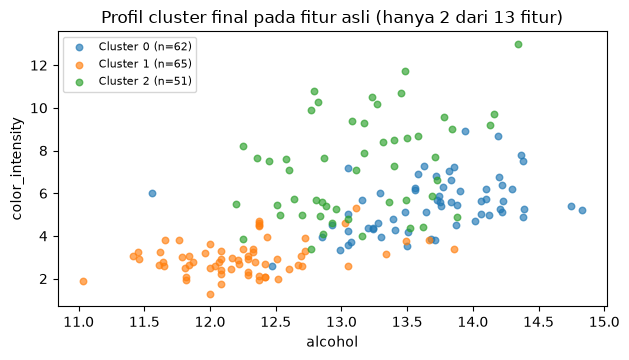

In [21]:
profile=X_raw.copy()
profile['cluster']=final_labels
size_profile=profile.groupby('cluster').size().rename('jumlah')
means_profile=profile.groupby('cluster')[['alcohol','color_intensity','proline']].mean()
cluster_profile=pd.concat([size_profile,means_profile],axis=1).round(3)
display(cluster_profile)
fig,ax=plt.subplots(figsize=(6.4,3.7))
for c,g in profile.groupby('cluster'):
    ax.scatter(g.alcohol,g.color_intensity,alpha=.65,s=22,label=f'Cluster {c} (n={len(g)})')
ax.set(title='Profil cluster final pada fitur asli (hanya 2 dari 13 fitur)',xlabel='alcohol',ylabel='color_intensity')
ax.legend(fontsize=8);plt.tight_layout();plt.show()

**✍️ Interpretasi P7-B (K-Means, k = 3, satuan asli):**

- **Cluster dengan `proline` tinggi** (±1100, `alcohol` ±13.7): kelompok beralkohol tinggi dengan `proline` jauh di atas rata-rata data (746.9).
- **Cluster dengan `alcohol` & `color_intensity` rendah** (±12.2 dan ±3.0, `proline` ±510): kelompok paling “ringan” secara alkohol dan warna.
- **Cluster dengan `color_intensity` tinggi** (±7.2, `proline` ±620): warna paling pekat dengan `proline` sedang.

Nomor cluster (0/1/2) bersifat arbitrer dan dapat berganti jika seed atau versi library berubah, jadi bacalah profilnya, bukan nomornya. Profil ini juga hanya memuat 3 dari 13 fitur, dan scatter `alcohol`–`color_intensity` hanya proyeksi 2D sehingga titik yang tampak tumpang-tindih bisa saja terpisah di dimensi lain. Cluster **tidak** boleh dibaca sebagai “anggur bagus/buruk” atau sebagai cultivar tanpa validasi domain.


### P7-C. Export tabel, konfigurasi, dan README untuk portofolio GitHub
**JALANKAN:** empat berkas dibuat otomatis pada folder `P08_output`. Setelah itu lengkapi laporan Markdown pada notebook. **README bawaan masih kerangka**, bukan kesimpulan pribadi; wajib diperbaiki sebelum publikasi.

In [22]:
import json
res=pd.DataFrame(EXPERIMENTS)
res.to_csv(OUTDIR/'P08_experiment_table.csv',index=False)
cluster_profile.to_csv(OUTDIR/'P08_cluster_profile.csv')
with open(OUTDIR/'P08_final_config.json','w',encoding='utf-8') as fh:
    json.dump(FINAL_CONFIG,fh,ensure_ascii=False,indent=2)
readme = f"""# P08 — Memilih Hierarchical atau K-Means berdasarkan EDA

**Dataset utama:** scikit-learn Wine, 178 sampel × 13 fitur numerik. Label target tidak digunakan.

## Pertanyaan proyek
Bagaimana pilihan scaling, feature selection, PCA, dan konteks pemakaian memengaruhi pemilihan Ward atau K-Means?

## Alur eksperimen
Audit data → baseline fair comparison → ablation → simulasi kualitas data → keputusan akhir → profil cluster.

## Keputusan final (perlu Anda jelaskan kembali dengan angka)
- Metode: {FINAL_CONFIG['method']}
- k: {FINAL_CONFIG['k']}
- Scaling: {FINAL_CONFIG['scaler']}
- Representasi: {FINAL_CONFIG['representation']}
- Clipping IQR: {FINAL_CONFIG['clip_iqr']}
- Silhouette pada ruang StandardScaler: {silhouette_score(X_std,final_labels):.4f}
- DBI pada ruang StandardScaler: {davies_bouldin_score(X_std,final_labels):.4f}
- Alasan: Wine bersih (0 missing, 0 duplikat) tetapi skalanya timpang (rasio rentang 2645×), sehingga wajib StandardScaler. Pada X_std yang sama, k=3 memberi silhouette tertinggi (K-Means 0.285 vs Ward 0.277) dan DBI K-Means 1.389. Dendrogram Ward menunjukkan lompatan merge ±12.6 → ±27.7 yang mendukung tiga cabang. K-Means dipilih karena paling stabil di semua ablation (0.280–0.285) dan terhadap outlier simulasi (0.278 vs Ward 0.260), serta centroidnya mudah ditafsirkan. Ward tetap alternatif wajar (ukuran cluster k=3 serupa) bila tujuan utamanya eksplorasi hierarki.

## Bukti
- Notebook utama `.ipynb` (soal, kode, output, interpretasi)
- `P08_experiment_table.csv`
- `P08_cluster_profile.csv`
- `P08_final_config.json`

## Keterbatasan
1. **Sensitif terhadap skala:** tanpa scaling, silhouette_common jatuh ke ≈0.11 karena `proline` mendominasi; hasil bergantung pada pilihan scaler.
2. **Pilihan k tidak mutlak:** silhouette k=3 hanya sedang (≈0.28) dan beda Ward–K-Means sangat kecil; k lain masih bisa dibela untuk tujuan berbeda.
3. **Makna domain belum divalidasi:** cluster adalah pola statistik, bukan kelas cultivar atau mutu; label target tidak dipakai, dan interpretasi kimia perlu ahli.
4. **Generalisasi & biaya:** scaler di-fit pada seluruh 178 sampel (eksplorasi deskriptif, tanpa evaluasi out-of-sample); Ward memerlukan matriks jarak O(n²) bila diterapkan pada data besar.

## Reproduksi
Python 3; NumPy; Pandas; SciPy; scikit-learn; Matplotlib. Jalankan notebook dari atas sampai bawah.
"""
(OUTDIR/'README_PORTOFOLIO_P08.md').write_text(readme,encoding='utf-8')
print('Berkas dibuat:')
for f in sorted(OUTDIR.iterdir()):print('-',f)

Berkas dibuat:
- P08_output\P08_cluster_profile.csv
- P08_output\P08_experiment_table.csv
- P08_output\P08_final_config.json
- P08_output\README_PORTOFOLIO_P08.md


### ✍️ LAPORAN AKHIR — Tulis langsung di notebook (tidak perlu DOCX terpisah)

**L1. Rumusan masalah (2–3 kalimat):** Apa objek dan tujuan pengelompokan? Mengapa clustering, bukan classification?

Objek analisis adalah 178 sampel anggur dari Wine Dataset (scikit-learn), masing-masing dengan 13 hasil ukur kimia; unit analisisnya satu sampel anggur. Tujuannya menemukan apakah sampel membentuk kelompok kimia yang mirip, lalu memilih secara beralasan antara Ward dan K-Means. Masalah ini diperlakukan sebagai clustering karena tidak ada label yang dipakai untuk melatih atau memilih model: label cultivar sengaja tidak digunakan, dan tujuannya eksplorasi struktur, bukan memprediksi kelas yang sudah diketahui.

**L2. Ringkasan EDA:** kutip minimal **lima temuan angka** dan satu keputusan preprocessing yang mengikuti temuan tersebut.

1. Ukuran 178 × 13, semua fitur `float64`, tidak ada fitur konstan.
2. Missing = 0 dan duplikat persis = 0, sehingga tidak perlu imputasi atau deduplikasi pada data asli.
3. Rasio rentang terbesar/terkecil = **2645.28** (`proline` 1402 vs `nonflavanoid_phenols` 0.53); median jarak pasangan raw 282.17 vs standardized 5.00.
4. Outlier 1.5×IQR sedikit: maksimal 4 per fitur (`magnesium`, `alcalinity_of_ash`, `color_intensity`), total 21 sel.
5. Korelasi tertinggi \|r\| = 0.865 (`total_phenols`–`flavanoids`), disusul 0.787 (`flavanoids`–`od280`).

**Keputusan:** karena temuan 3, semua model memakai **StandardScaler**. Outlier tidak dihapus (temuan 4), dan redundansi (temuan 5) hanya diuji lewat ablation, bukan langsung dibuang.

**L3. Ablation P1–P7:** sebutkan sedikitnya **tiga eksperimen sah**, perubahan masing-masing, metrik pada ruang evaluasi yang sama, serta pengaruh terhadap interpretasi.

Semua dengan k = 3 dan evaluasi pada X_std yang sama:
1. **Scaling (STD → RAW):** K-Means silhouette_common 0.285 → 0.108, DBI 1.389 → 3.364. Tanpa scaling, cluster hanya mencerminkan `proline`, sehingga interpretasinya bias ke satu fitur.
2. **Feature selection (13 → 12, buang `flavanoids`):** Ward 0.277 → 0.270, K-Means 0.285 → 0.284. Hampir tidak berubah, jadi fitur redundan tidak mengganggu, dan membuangnya menghilangkan informasi kimia yang bermakna.
3. **PCA 90% (13 → 8 komponen, EVR 0.920):** silhouette_fit naik (Ward 0.277 → 0.305), tetapi silhouette_common tetap ±0.275–0.285. Kenaikan skor fit adalah efek reduksi dimensi, bukan cluster yang lebih baik, sementara komponen PCA lebih sulit ditafsirkan.
4. **Outlier simulasi (proline × 8, n tetap 178):** Ward 0.277 → 0.260, K-Means 0.285 → 0.278. Satu nilai ekstrem sudah cukup mengubah partisi Ward lebih banyak daripada K-Means.

**L4. Mengapa memilih Ward/K-Means untuk Wine?** Sebutkan k dan minimal dua metrik numerik. Jelaskan peran dendrogram atau centroid, biaya komputasi, dan apakah alternatif berbeda mungkin tetap wajar.

Saya memilih **K-Means, k = 3, StandardScaler, 13 fitur, tanpa clipping**. Hasilnya: silhouette_common **0.285** dan DBI_common **1.389**, sedikit lebih baik daripada Ward (0.277 / 1.419), dengan ukuran cluster seimbang 51/62/65. K-Means juga paling stabil di semua ablation (0.280–0.285) dan saat ada outlier simulasi. Centroidnya memberi profil rata-rata yang langsung bisa dibaca dalam satuan asli dan bisa dipakai untuk menempatkan sampel baru. Biaya komputasi tidak menjadi pembeda di sini karena n = 178 (matriks jarak ±0,2 MB). Dendrogram Ward tetap saya pakai sebagai **validasi pilihan k**: lompatan tinggi merge dari ±12.6 ke ±27.7 menunjukkan tiga cabang utama. Ward k = 3 juga **tetap wajar** sebagai alternatif, karena selisih silhouette hanya 0.008 dan ukuran cluster mirip (56/58/64), terutama jika pengguna lebih membutuhkan struktur bertingkat.

**L5. Dua kondisi data:** bandingkan kesimpulan Wine nyata dengan data besar sintetis. Jelaskan mengapa kondisi data dan tujuan aplikasi, bukan sekadar angka silhouette, berpengaruh pada pilihan.

Pada Wine (178 × 13, skala timpang, struktur sedang dengan silhouette ≈0.28), tujuannya eksplorasi, sehingga dendrogram berguna untuk membenarkan k dan melihat hierarki. Pilihan antara Ward dan K-Means pun tipis. Pada data sintetis (3000 × 2, tiga gumpalan kompak), Ward dan K-Means menghasilkan kualitas **identik** pada subsampel adil n = 450 (silhouette 0.715, DBI 0.406 vs 0.405). Jadi silhouette **tidak bisa** menentukan pilihan di sana. Yang menentukan adalah tujuan segmentasi (butuh centroid untuk `predict`), tidak adanya kebutuhan hierarki, dan biaya memori matriks jarak yang tumbuh O(n²) (≈68.7 MB pada n = 3000, ≈763 MB pada n = 10.000). Sebaliknya, P6-C *make_moons* menunjukkan bahwa ketika bentuk data tidak kompak, **keduanya** gagal, sehingga karakter data bisa menuntut metode lain.

**L6. Analisis keterbatasan & penggunaan bertanggung jawab (min. 3):** misalnya skala, PCA, makna cluster, stabilitas, outlier, keterulangan, pembatasan generalisasi.

1. **Skala & preprocessing:** hasil sangat bergantung pada scaling (silhouette 0.285 vs 0.108). Perubahan preprocessing harus dicatat agar hasil bisa direproduksi.
2. **Kekuatan struktur terbatas:** silhouette ≈0.28 berarti cluster tumpang-tindih sebagian. Jumlah k = 3 adalah pilihan yang paling didukung bukti, bukan kebenaran mutlak.
3. **Makna cluster:** cluster bukan cultivar dan bukan penilaian mutu. Label tidak dipakai, dan penamaan cluster butuh validasi ahli kimia/enologi.
4. **Stabilitas & keterulangan:** hasil K-Means bergantung pada seed (2026, n_init = 20) dan versi library (scikit-learn 1.9.1, SciPy 1.18.1). Nomor cluster bisa berganti.
5. **Generalisasi:** scaler dan model di-fit pada seluruh data untuk eksplorasi deskriptif. Klaim untuk sampel anggur baru memerlukan desain fit/evaluasi terpisah.
6. **Simulasi P5:** missing, duplikat, dan outlier di P5 adalah buatan, bukan sifat Wine asli.

**L7. Refleksi profesional (3–5 kalimat):** Apa satu keputusan Anda yang berubah setelah melihat EDA/hasil eksperimen? Bagaimana Anda memverifikasinya?

Awalnya saya cenderung memilih Ward untuk Wine karena datanya kecil dan dendrogramnya informatif, seperti contoh konfigurasi bawaan. Setelah melihat tabel P4 dan P5-B, saya berubah ke K-Means: pada ruang evaluasi yang sama skornya sedikit lebih baik dan jauh lebih stabil terhadap satu outlier buatan (Ward turun 0.017, K-Means hanya 0.007). Saya juga hampir menganggap PCA sebagai perbaikan karena silhouette fit-nya naik ke 0.305–0.315, tetapi setelah membandingkan silhouette_common yang tidak berubah, saya menyimpulkan kenaikan itu hanya efek ruang evaluasi. Verifikasinya dilakukan dengan menjalankan ulang notebook dari atas ke bawah dan mencocokkan angka di tabel eksperimen yang diekspor (`P08_experiment_table.csv`).

**L8. Tautan portofolio (setelah commit):** `https://github.com/.../commit/...` (pakai URL commit spesifik untuk versi yang dinilai).

## CHECKLIST PENGUMPULAN DAN PENILAIAN

- [ ] Semua cell berjalan dari atas ke bawah (*Restart & Run All*) tanpa error.
- [ ] Setiap bagian P1–P7 dan L1–L8 memiliki jawaban nyata, bukan `ISI...`.
- [ ] P2 memuat sedikitnya lima temuan EDA dengan angka.
- [ ] P3 membandingkan kedua algoritma pada **data dan k yang sama**.
- [ ] P4 menunjukkan sedikitnya tiga ablation yang sah.
- [ ] P5 menyebutkan data bermasalah adalah **simulasi**, bukan Wine asli.
- [ ] P6 membedakan kebutuhan hierarki vs kepraktisan centroid & biaya pada ukuran berbeda.
- [ ] P7 membahas cluster profile pada fitur asli dan batas interpretasi.
- [ ] Berkas ekspor tersedia di `P08_output`; notebook dengan output disimpan.
- [ ] GitHub: unggah notebook final + README yang sudah ditulis ulang. Jangan unggah data berlisensi/privat tanpa izin.

